# A3 DQN core + baselines + strategy 3

The shared DQN code is in core/ and the curriculum (strategy 3) is in strategies/curriculum.py. This notebook runs the experiments and makes the plots. Training cells skip runs that already finished so they can just be rerun.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from core.config import Cfg
from core.env import VAL_LENS
from train import launch, run_name

SEEDS = list(range(10))
PROCS = 10  #parallel runs, 1 cpu thread each

## Setup

Everything below is the same for all methods so the only thing that changes between them is how the pole length gets picked each episode.

The network is the standard QNetwork from test_script.py. It's trained with double DQN using Huber loss and Adam, with one update every 4 env steps and a hard target network copy every 1000 env steps. Epsilon goes down linearly over the first 20% of the steps. The settings come from the two pilots below.

The reward is +1 per step minus a penalty for pole angle and cart position: $r = 1 - 0.5|\theta|/\theta_{max} - 0.5|x|/x_{max}$

There is no 500 step cutoff. Train episodes stop at 1000 steps but that's not stored as done so Q still bootstraps past it.

Every 10k steps the greedy policy is run on our own val lengths (the bin centres, not the test lengths) with normal dynamics and fixed seeds. Val score is the shaped return over 1000 steps divided by 1000 so 1 means it balanced perfectly the whole time. The checkpoint with the best mean val score is saved as weights/{run}.pth.

The problem is that normal val saturates. Most checkpoints get around 0.98 so the best one says almost nothing about the test, where the force goes up after step 500. So every val round also does a stress val: same lengths and start states but with the exact force changes from test_pole_length, capped at 2000 steps. Stress score = steps survived / 2000. The best stress checkpoint is saved as weights/{run}_stress.pth (ties broken by normal val). Stress val is only used to pick a checkpoint, never for training and never by the curriculum. We still have to check with the TA which of the 2 checkpoints we're allowed to submit.

In [2]:
#default hyperparams, table for the methods section
pd.Series(Cfg().dict(), name='value').to_frame()

,value
name,run
seed,0
steps,400000
max_ep,1000
lo,0.4
hi,1.8
w_ang,0.5
w_pos,0.5
gamma,0.99
lr,0.00025


## Pilot

Small lr sweep on the uniform baseline to pick the lr and see how many steps are needed. Seeds 100 and 101 so they don't overlap with the real runs. Only the val score is used for this, not the test script.

In [3]:
#pilot 1 used the first settings: update every step + soft tgt update
OLD = ['steps=400000', 'train_freq=1', 'tau=0.005', 'tgt_every=1']
PILOT_LRS = [1e-3, 5e-4, 2.5e-4]

pilot = [('uniform', s, [f'lr={lr}'] + OLD, f'_lr{lr:g}', 'pilot') for lr in PILOT_LRS for s in (100, 101)]
launch(pilot, PROCS)

6 done, 0 to run


In [4]:
def load_val(names, root='.'):
    #val logs of several runs stacked
    dfs = []
    for n in names:
        df = pd.read_csv(f'{root}/runs/{n}/val.csv')
        df['run'] = n
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


def plot_val(groups, root='.', ax=None, col='score'):
    #mean +- std of a val column over seeds per group
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4))

    for label, names in groups.items():
        g = load_val(names, root).groupby('step')[col]
        m, s = g.mean(), g.std().fillna(0)
        ax.plot(m.index, m, label=label)
        ax.fill_between(m.index, m - s, m + s, alpha=0.2)

    ax.set_xlabel('env steps')
    ax.set_ylabel(f'val {col}')
    ax.legend()
    ax.grid(alpha=0.3)
    return ax


def best_rows(names, root='.'):
    #val row of the normal ckpt per run
    df = load_val(names, root)
    return df.loc[df.groupby('run')['score'].idxmax()]


def stress_rows(names, root='.'):
    #val row of the stress ckpt per run, same tie break as the trainer
    df = load_val(names, root)
    return df.sort_values(['stress', 'score', 'step'], ascending=[True, True, False]).groupby('run').tail(1)

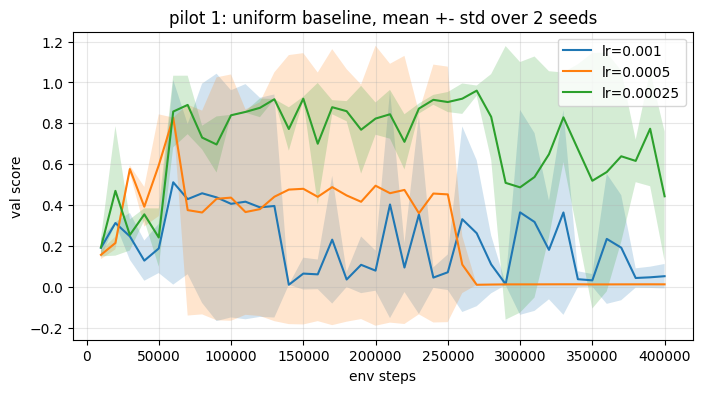

run    step     score
lr=0.001   1     uniform_lr0.001_s100   20000  0.315140
           48    uniform_lr0.001_s101   90000  0.865489
lr=0.0005  5    uniform_lr0.0005_s100   60000  0.827872
           59   uniform_lr0.0005_s101  200000  0.978945
lr=0.00025 6   uniform_lr0.00025_s100   70000  0.991075
           72  uniform_lr0.00025_s101  330000  0.984285

In [5]:
pilot_groups = {f'lr={lr:g}': [run_name('uniform', s, f'_lr{lr:g}') for s in (100, 101)] for lr in PILOT_LRS}
plot_val(pilot_groups, 'pilot').set_title('pilot 1: uniform baseline, mean +- std over 2 seeds')
plt.show()

#best ckpt per run, where in training it happened
pd.concat({k: best_rows(v, 'pilot')[['run', 'step', 'score']] for k, v in pilot_groups.items()})

## Pilot 2

Pilot 1 was really unstable. With lr 1e-3 and 5e-4 the Q values blew up (one run went to 1e10 while the max possible is 100 with $\gamma = 0.99$ and reward $\leq 1$) and the agent ended up falling in about 10 steps. Even 2.5e-4 had big drops and one seed ended with Q values around 170. Part of the problem is doing an update every env step. Also without the 500 cutoff a good agent hardly ever fails so there aren't many failures left in the buffer.

So pilot 2 keeps lr 2.5e-4 and switches to more standard DQN settings: one update every 4 steps and a hard target copy every 1000 env steps (Mnih et al. 2015). On top of that it tries $\gamma = 0.98$ (smaller Q values) and a 400k buffer (keeps all the early failures).

In [6]:
STD = ['lr=0.00025', 'steps=400000', 'train_freq=4', 'tau=1', 'tgt_every=250']
PILOT2 = {'_std': STD,
          '_g98': STD + ['gamma=0.98'],
          '_buf400': STD + ['buf=400000'],
          '_g98buf400': STD + ['gamma=0.98', 'buf=400000']}

launch([('uniform', s, kv, tag, 'pilot') for tag, kv in PILOT2.items() for s in (100, 101)], PROCS)

8 done, 0 to run


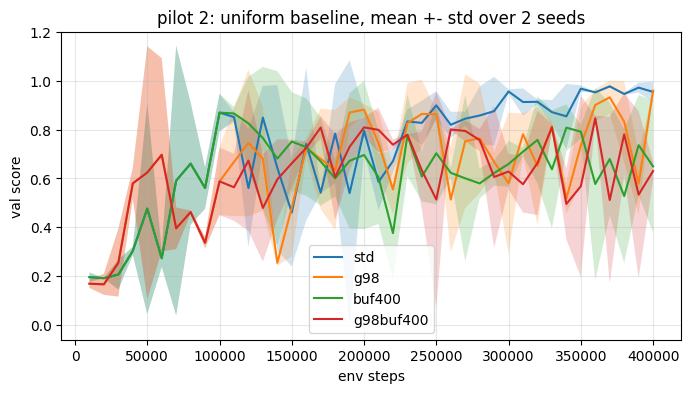

,cfg,best,late_mean,late_min,q_upright
0,lr=0.001,0.590,0.178,0.010,8.502331e+10
1,lr=0.0005,0.903,0.124,0.010,1.487906e+10
2,lr=0.00025,0.988,0.710,0.036,1.336040e+02
3,std,0.984,0.875,0.504,9.544900e+01
4,g98,0.985,0.742,0.361,4.871700e+01
5,buf400,0.977,0.651,0.242,9.412100e+01
6,g98buf400,0.922,0.673,0.201,4.802100e+01


In [7]:
import torch
from test_script import QNetwork


def q_upright(run, root='pilot'):
    #max Q of the final net at the upright state, real max is 1 / (1 - gamma)
    q = QNetwork(4, 2)
    q.load_state_dict(torch.load(f'{root}/runs/{run}/final.pth'))
    return q(torch.zeros(1, 4)).max().item()


pilot2_groups = {tag[1:]: [run_name('uniform', s, tag) for s in (100, 101)] for tag in PILOT2}
plot_val(pilot2_groups, 'pilot').set_title('pilot 2: uniform baseline, mean +- std over 2 seeds')
plt.show()

#stability after 200k steps for both pilots
rows = []
for k, names in {**pilot_groups, **pilot2_groups}.items():
    df = load_val(names, 'pilot')
    late = df[df.step > 200_000]
    rows.append({'cfg': k, 'best': df.groupby('run')['score'].max().mean(),
                 'late_mean': late['score'].mean(), 'late_min': late['score'].min(),
                 'q_upright': np.median([q_upright(n) for n in names])})

pd.DataFrame(rows).round(3)

std wins. It has the highest late mean (0.88 and 0.87 for the 2 seeds) and no collapse, and Q at the upright state is about 95 which is close to the real max of 100. $\gamma = 0.98$ and the big buffer both made it less stable. So the defaults in core/config.py are now lr 2.5e-4, one update every 4 steps, hard target copy every 1000 env steps, $\gamma = 0.99$ and 400k steps per run. It's only 2 seeds per setting so this is just for picking settings and not a result.

## Baselines

fixed: always length 0.5 (normal cartpole)

uniform: random length between 0.4 and 1.8 every episode. This is the main one we compare against.

In [8]:
BASE = []  #defaults in core/config.py are already the pilot 2 std settings
launch([(m, s, BASE, '', '.') for m in ('fixed', 'uniform') for s in SEEDS], PROCS)

20 done, 0 to run


## Strategy 3: curriculum

0.4 to 1.8 is split into $K = 10$ bins and the bin centres are the val lengths. After every val round each bin gets a regret of 1 - val score. The bins are ranked on regret (worst bin is rank 1) and sampled with

$$p_i = (1-\lambda)\frac{h_i}{\sum_j h_j} + \frac{\lambda}{K}, \qquad h_i = \text{rank}_i^{-1/T}$$

This is the rank prioritisation from prioritized level replay (Jiang et al. 2021). The $\lambda/K$ part mixes in uniform sampling ($\lambda = 0.2$) so the easy lengths don't get forgotten. Every bin gets rescored each round so the staleness part from PLR isn't needed. Inside a bin the length is uniform so it doesn't only train on the val lengths.

In [9]:
launch([('curriculum', s, BASE, '', '.') for s in SEEDS], PROCS)

10 done, 0 to run


## Control: reversed curriculum

To check that it's really the focus on the hard lengths that matters and not just training on some non uniform mix, the same sampler also runs the other way around: the easiest bins get the high probs (cl_prio = anti). Same $T$ and $\lambda$.

In [10]:
launch([('curriculum', s, ['cl_prio=anti'], '_anti', '.') for s in SEEDS], PROCS)

10 done, 0 to run


## Results on the val lengths

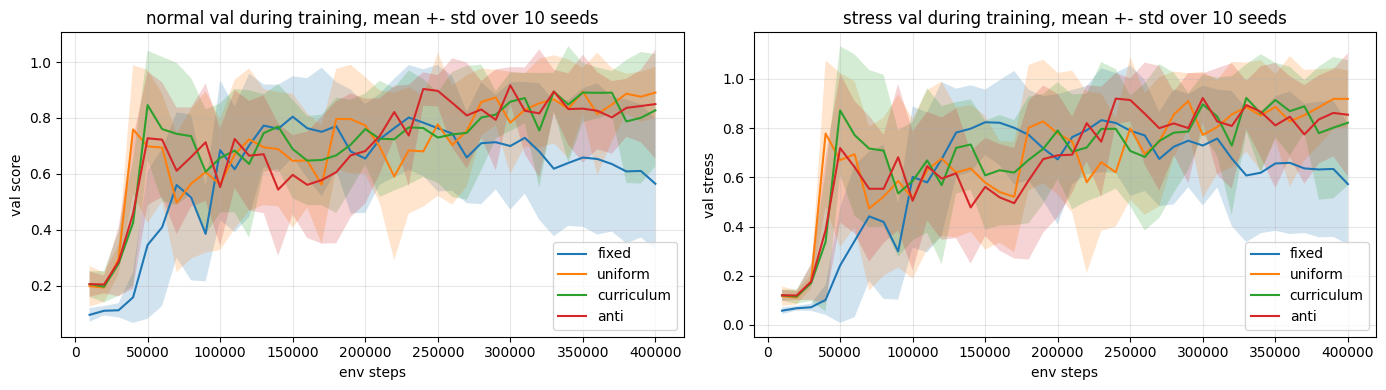

In [11]:
#method -> run names over the seeds
RUNS = {'fixed': ('fixed', ''), 'uniform': ('uniform', ''),
        'curriculum': ('curriculum', ''), 'anti': ('curriculum', '_anti')}
METHODS = list(RUNS)
groups = {k: [run_name(m, s, tag) for s in SEEDS] for k, (m, tag) in RUNS.items()}

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
plot_val(groups, ax=axs[0], col='score').set_title(f'normal val during training, mean +- std over {len(SEEDS)} seeds')
plot_val(groups, ax=axs[1], col='stress').set_title(f'stress val during training, mean +- std over {len(SEEDS)} seeds')
fig.tight_layout()
plt.show()

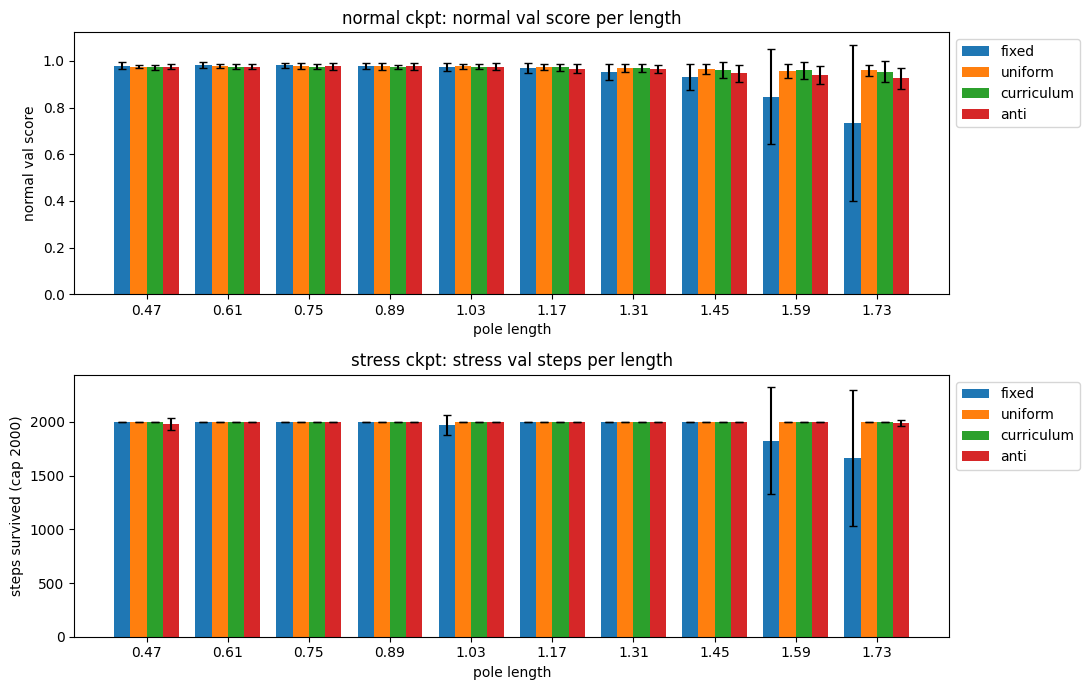

In [12]:
#per len val of the 2 saved ckpts
x = np.arange(len(VAL_LENS))
w = 0.8 / len(METHODS)

fig, axs = plt.subplots(2, 1, figsize=(11, 7))

for i, m in enumerate(METHODS):
    b = best_rows(groups[m])[[f's_{l:.2f}' for l in VAL_LENS]]
    axs[0].bar(x + i * w, b.mean(), w, yerr=b.std(), capsize=3, label=m)

    b = stress_rows(groups[m])[[f't_{l:.2f}' for l in VAL_LENS]]
    axs[1].bar(x + i * w, b.mean(), w, yerr=b.std(), capsize=3, label=m)

for ax in axs:
    ax.set_xticks(x + 1.5 * w, [f'{l:.2f}' for l in VAL_LENS])
    ax.set_xlabel('pole length')
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

axs[0].set_ylabel('normal val score')
axs[0].set_title('normal ckpt: normal val score per length')
axs[1].set_ylabel('steps survived (cap 2000)')
axs[1].set_title('stress ckpt: stress val steps per length')
fig.tight_layout()
plt.show()

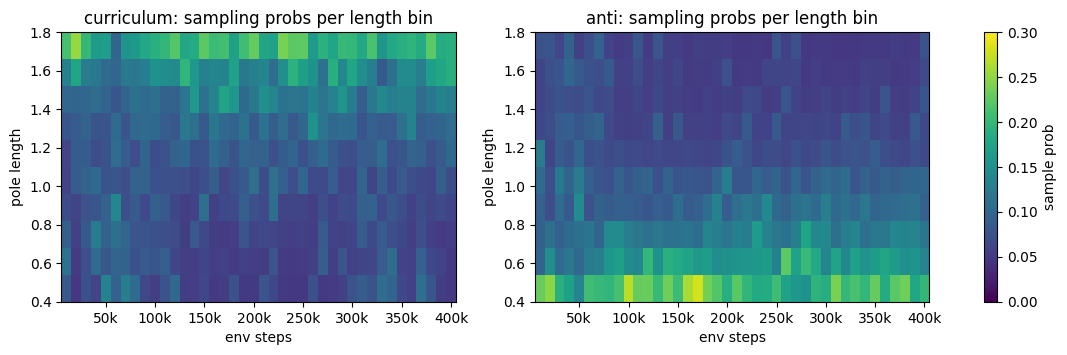

In [13]:
#where the curriculum puts its samples over training, mean over seeds
pcols = [f'p_{l:.2f}' for l in VAL_LENS]

fig, axs = plt.subplots(1, 2, figsize=(14, 3.5))

for ax, m in zip(axs, ['curriculum', 'anti']):
    p = load_val(groups[m]).groupby('step')[pcols].mean()
    im = ax.pcolormesh(p.index, VAL_LENS, p.T.values, shading='nearest', cmap='viridis', vmin=0, vmax=0.3)
    ax.xaxis.set_major_formatter(lambda x, _: f'{x / 1000:.0f}k')
    ax.set_xlabel('env steps')
    ax.set_ylabel('pole length')
    ax.set_title(f'{m}: sampling probs per length bin')

fig.colorbar(im, ax=axs, label='sample prob')
plt.show()

In [14]:
#training cost and when the 2 ckpts were found
rows = []
for m in METHODS:
    for n in groups[m]:
        df = pd.read_csv(f'runs/{n}/val.csv')
        rows.append({'method': m, 'normal_step': df.loc[df['score'].idxmax(), 'step'],
                     'stress_step': stress_rows([n])['step'].iloc[0],
                     'wall_min': df['time'].iloc[-1] / 60, 'val_steps': df['val_steps'].iloc[-1]})

pd.DataFrame(rows).groupby('method').agg(['mean', 'std']).round(1).loc[METHODS]

normal_step           stress_step           wall_min       \
                  mean       std        mean       std     mean  std   
method                                                                 
fixed         225000.0  106588.5    195000.0   76485.3      5.4  0.4   
uniform       243000.0  139367.6    237000.0  122388.3      6.0  0.6   
curriculum    258000.0   98522.4    251000.0  109691.5      5.8  0.2   
anti          328000.0   58080.4    241000.0  102788.9      5.8  0.2   

            val_steps            
                 mean       std  
method                           
fixed       2261364.8  460522.6  
uniform     2600423.0  335966.5  
curriculum  2646702.2  165943.5  
anti        2579438.3  156070.4

## Test protocol

Both checkpoints of every run go through evaluate.py. That runs the unchanged test_pole_length from the test script on the 30 test lengths with 10 episodes each and fixed start states. This only happens after all training is done and nothing from it is used to train or pick anything.

In [15]:
import os
import subprocess
import sys

from scipy import stats

TEST_CSV = 'test_results.csv'
nets = [f'weights/{n}{c}.pth' for m in METHODS for n in groups[m] for c in ('', '_stress')]

#only test the nets that aren't in the csv yet
os.makedirs('results', exist_ok=True)
done = set(pd.read_csv(TEST_CSV)['net']) if os.path.exists(TEST_CSV) else set()
todo = [n for n in nets if os.path.basename(n)[:-4] not in done]

if todo:
    subprocess.run([sys.executable, 'evaluate.py', *todo, '--out', 'results/new.csv', '--procs', str(PROCS)], check=True)
    old = [pd.read_csv(TEST_CSV)] if done else []
    pd.concat(old + [pd.read_csv('results/new.csv')]).to_csv(TEST_CSV, index=False)
    os.remove('results/new.csv')

test = pd.read_csv(TEST_CSV)
test = test[test['net'].isin([os.path.basename(n)[:-4] for n in nets])]
test['ckpt'] = np.where(test['net'].str.endswith('_stress'), 'stress', 'normal')
test['run'] = test['net'].str.replace('_stress', '', regex=False)
test['method'] = test['run'].map({n: m for m in METHODS for n in groups[m]})

#avg over 30 lens x 10 eps per net, then mean +- std over the seeds
per_net = test.groupby(['method', 'ckpt', 'run'])['steps'].mean()
per_net.groupby(['method', 'ckpt']).agg(['mean', 'std', 'min', 'max']).round(0).loc[METHODS]

mean      std      min      max
method     ckpt                                      
fixed      normal  23868.0   7527.0  14284.0  37727.0
           stress  27391.0   8334.0  17213.0  37727.0
uniform    normal  24626.0  13564.0   4529.0  51568.0
           stress  31429.0   8930.0  20108.0  51568.0
curriculum normal  30023.0  12649.0  13835.0  47112.0
           stress  31601.0  11319.0  13913.0  47112.0
anti       normal  25652.0  11064.0  15098.0  43096.0
           stress  24824.0  10156.0  15098.0  45214.0

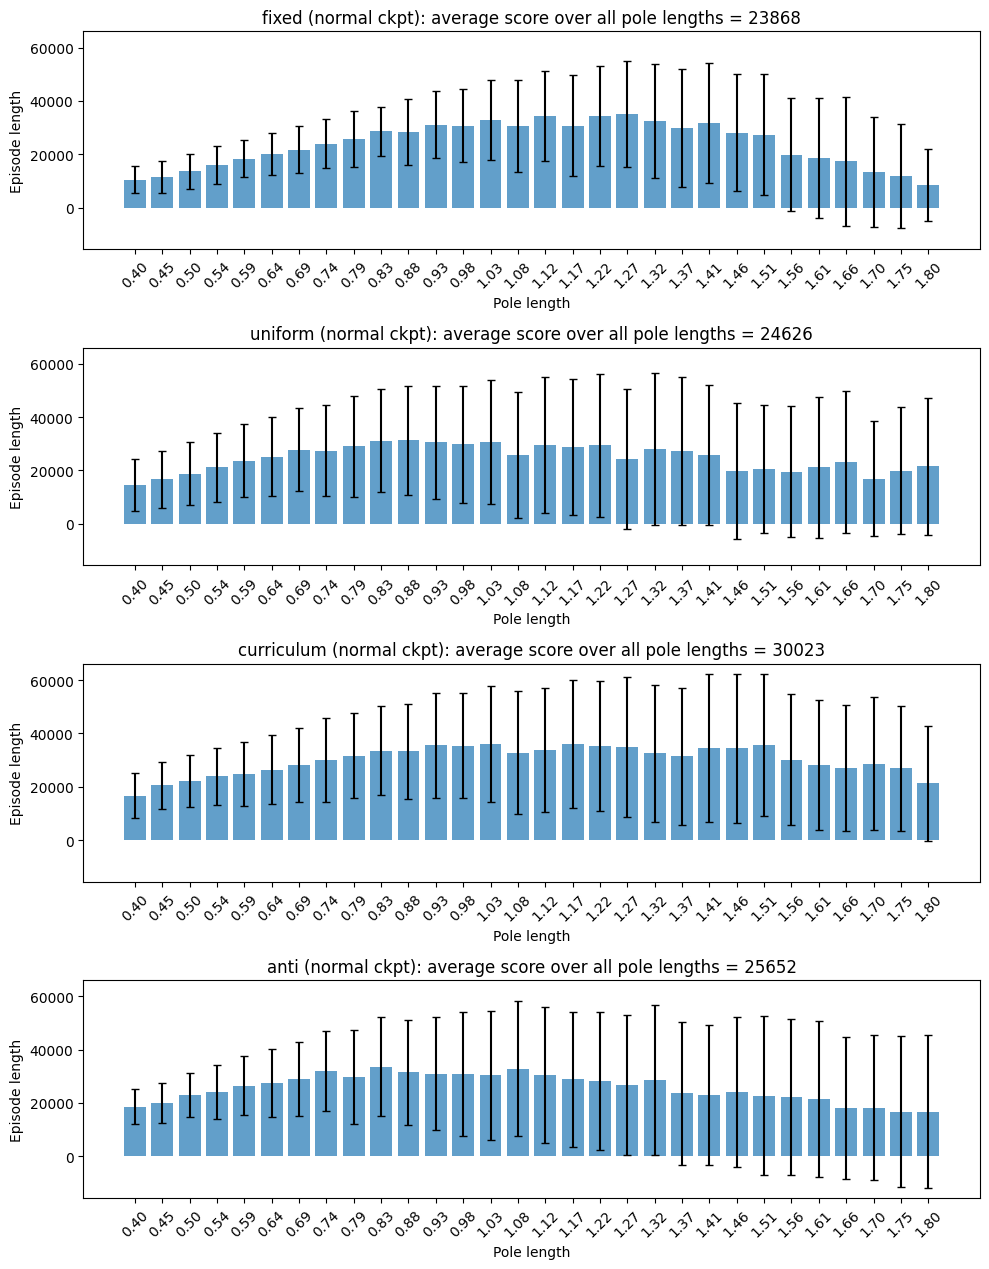

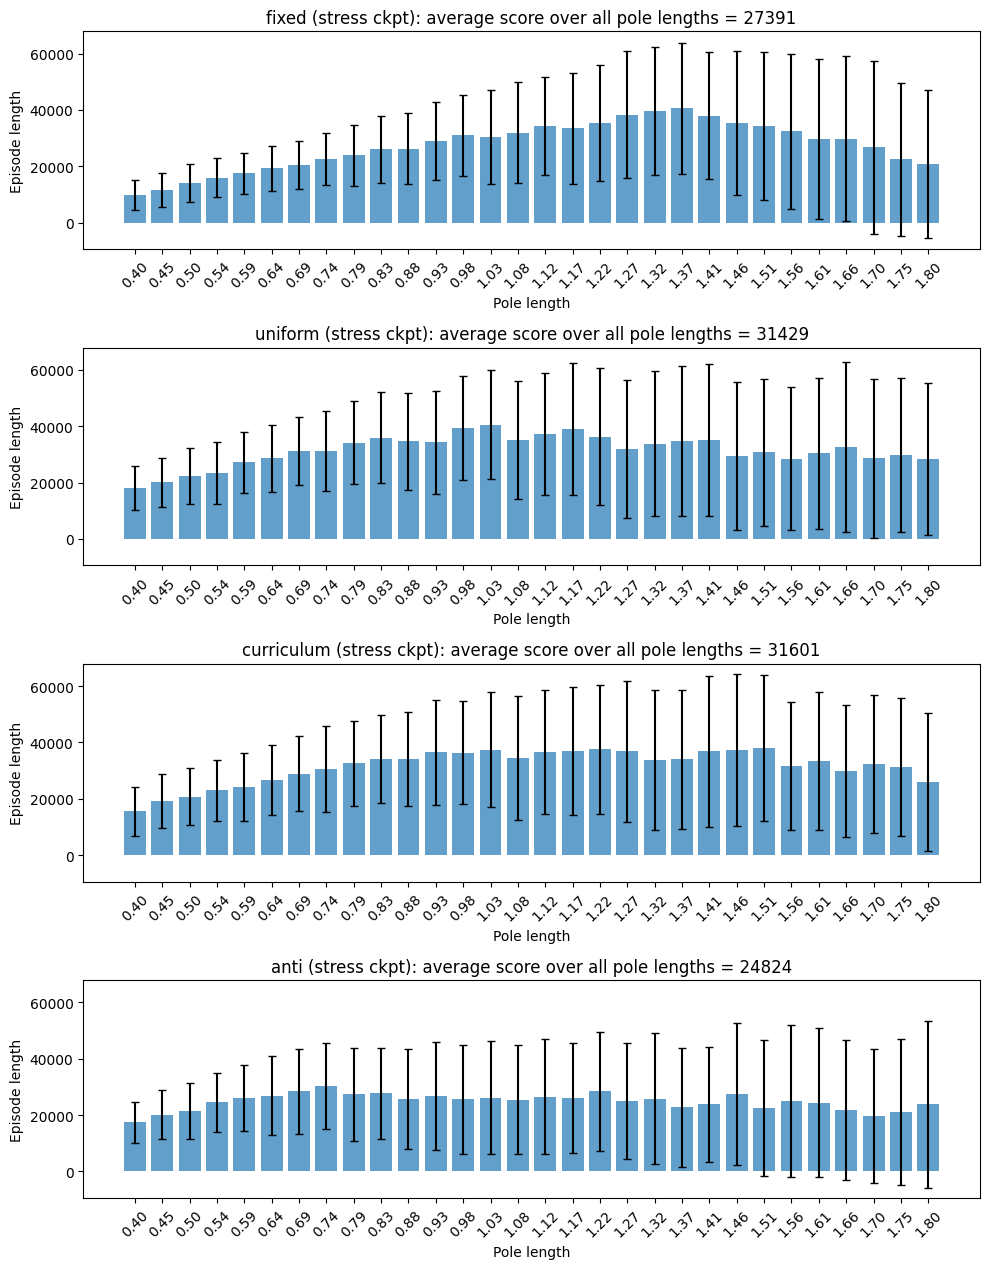

In [16]:
#bar plot like the test script: avg +- std per length, all seeds x 10 eps pooled
def bar_plot(df, ax, title):
    g = df.groupby('len')['steps']
    m, s = g.mean(), g.std()

    ax.bar(range(len(m)), m, yerr=s, capsize=3, alpha=0.7)
    ax.set_xticks(range(len(m)), [f'{l:.2f}' for l in m.index], rotation=45)
    ax.set_xlabel('Pole length')
    ax.set_ylabel('Episode length')
    ax.set_title(f'{title}: average score over all pole lengths = {m.mean():.0f}')


for ck in ('normal', 'stress'):
    fig, axs = plt.subplots(len(METHODS), 1, figsize=(10, 3.2 * len(METHODS)), sharey=True)

    for ax, m in zip(axs, METHODS):
        bar_plot(test[(test['method'] == m) & (test['ckpt'] == ck)], ax, f'{m} ({ck} ckpt)')

    fig.tight_layout()
    plt.show()

The stats are per seed (n = 10 per method) since the 10 episodes of one net are not independent runs of the method. Welch t-test and Mann-Whitney U, both two sided.

In [17]:
def compare(a, b, ck):
    x, y = per_net.loc[a, ck].values, per_net.loc[b, ck].values
    return {'a': a, 'b': b, 'ckpt': ck, 'mean_a': x.mean(), 'mean_b': y.mean(),
            'welch_p': stats.ttest_ind(x, y, equal_var=False).pvalue,
            'mwu_p': stats.mannwhitneyu(x, y, alternative='two-sided').pvalue}


pairs = [('curriculum', 'uniform'), ('curriculum', 'anti'), ('uniform', 'fixed'), ('curriculum', 'fixed')]
pd.DataFrame([compare(a, b, ck) for a, b in pairs for ck in ('normal', 'stress')]).round(3)

,a,b,ckpt,mean_a,mean_b,welch_p,mwu_p
0,curriculum,uniform,normal,30023.418,24625.933,0.370,0.427
1,curriculum,uniform,stress,31600.821,31428.501,0.970,1.000
2,curriculum,anti,normal,30023.418,25651.548,0.422,0.571
3,curriculum,anti,stress,31600.821,24824.215,0.176,0.162
4,uniform,fixed,normal,24625.933,23868.285,0.879,0.910
5,uniform,fixed,stress,31428.501,27391.056,0.310,0.385
6,curriculum,fixed,normal,30023.418,23868.285,0.206,0.273
7,curriculum,fixed,stress,31600.821,27391.056,0.357,0.521


In [18]:
#does picking the ckpt on stress val help, paired over the same runs
d = per_net.unstack('ckpt')
w = stats.wilcoxon(d['stress'], d['normal'])
print(f'stress ckpt - normal ckpt: mean diff {(d["stress"] - d["normal"]).mean():.0f} steps, '
      f'wilcoxon p = {w.pvalue:.4f}, n = {len(d)}')

d.groupby('method').mean().round(0).loc[METHODS]

stress ckpt - normal ckpt: mean diff 2769 steps, wilcoxon p = 0.0486, n = 40


ckpt,normal,stress
method,,
fixed,23868.0,27391.0
uniform,24626.0,31429.0
curriculum,30023.0,31601.0
anti,25652.0,24824.0


In [19]:
#which test phase each episode ends in: 1 = normal (<= 500), 2 = force 75 (501-1000), 3 = force ramp (> 1000)
test['phase'] = pd.cut(test['steps'], [0, 500, 1000, np.inf], labels=['1 normal', '2 force 75', '3 ramp'])
pd.crosstab([test['method'], test['ckpt']], test['phase'], normalize='index').round(2).loc[METHODS]

phase              1 normal  2 force 75  3 ramp
method     ckpt                                
fixed      normal      0.04        0.05    0.91
           stress      0.03        0.02    0.95
uniform    normal      0.05        0.03    0.91
           stress      0.00        0.00    1.00
curriculum normal      0.00        0.02    0.98
           stress      0.00        0.01    0.99
anti       normal      0.01        0.03    0.96
           stress      0.00        0.00    1.00

In [20]:
#how well each val predicts the test score of the ckpt it picked, spearman over all runs
names = [n for m in METHODS for n in groups[m]]
v = pd.concat([best_rows(names).assign(ckpt='normal'), stress_rows(names).assign(ckpt='stress')]).set_index(['ckpt', 'run'])
t = per_net.reset_index().set_index(['ckpt', 'run'])['steps']

for ck, col in [('normal', 'score'), ('stress', 'stress')]:
    r = stats.spearmanr(v.loc[ck, col], t.loc[ck].reindex(v.loc[ck].index))
    print(f'{ck} ckpt: spearman({col} val, test avg) = {r.correlation:.2f}, p = {r.pvalue:.3f}')

normal ckpt: spearman(score val, test avg) = -0.11, p = 0.512
stress ckpt: spearman(stress val, test avg) = 0.16, p = 0.314


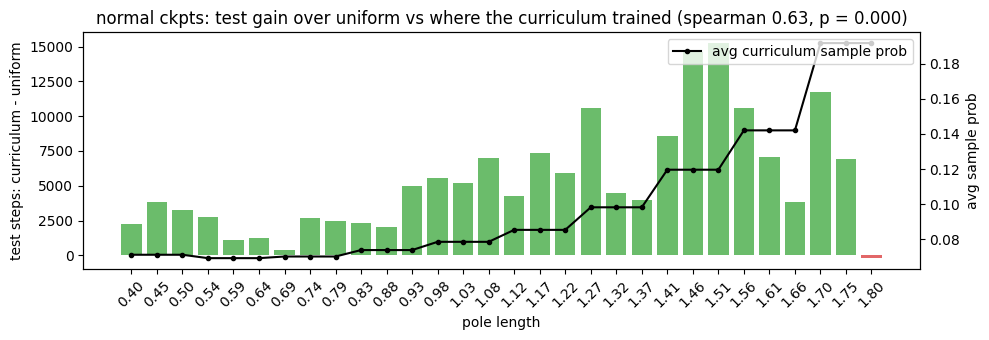

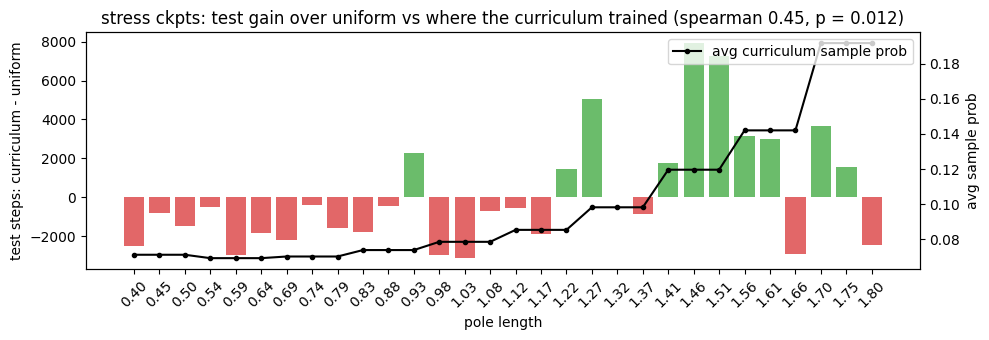

In [21]:
#did the lengths the curriculum trained on more get better than with uniform
#test gain per test length vs the avg sample prob of the bin that length falls in
edges = np.concatenate([[0.4], (np.array(VAL_LENS[1:]) + np.array(VAL_LENS[:-1])) / 2, [1.8]])
p_bin = load_val(groups['curriculum'])[pcols].mean().values

for ck in ('normal', 'stress'):
    cur = test[(test['method'] == 'curriculum') & (test['ckpt'] == ck)].groupby('len')['steps'].mean()
    uni = test[(test['method'] == 'uniform') & (test['ckpt'] == ck)].groupby('len')['steps'].mean()
    gain = cur - uni
    p_len = p_bin[np.clip(np.digitize(gain.index, edges[1:-1]), 0, len(p_bin) - 1)]

    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.bar(range(len(gain)), gain, color=np.where(gain > 0, 'tab:green', 'tab:red'), alpha=0.7)
    ax.set_xticks(range(len(gain)), [f'{l:.2f}' for l in gain.index], rotation=45)
    ax.set_xlabel('pole length')
    ax.set_ylabel('test steps: curriculum - uniform')

    ax2 = ax.twinx()
    ax2.plot(range(len(gain)), p_len, 'k.-', label='avg curriculum sample prob')
    ax2.set_ylabel('avg sample prob')
    ax2.legend(loc='upper right')

    r = stats.spearmanr(p_len, gain)
    ax.set_title(f'{ck} ckpts: test gain over uniform vs where the curriculum trained (spearman {r.correlation:.2f}, p = {r.pvalue:.3f})')
    fig.tight_layout()
    plt.show()

## Which net to submit

Picked per method on val only (best seed by val, ties broken by normal val), never on the test score. The test score is only shown next to it afterwards.

In [22]:
#best seed per method by val only, test avg just shown next to it
rows = []
for m in METHODS:
    for ck, keys in [('normal', ['score']), ('stress', ['stress', 'score'])]:
        v = best_rows(groups[m]) if ck == 'normal' else stress_rows(groups[m])
        b = v.sort_values(keys).iloc[-1]
        net = b['run'] + ('_stress' if ck == 'stress' else '')
        rows.append({'method': m, 'ckpt': ck, 'net': net, 'val': b[keys[0]],
                     'test_avg': test.loc[test['net'] == net, 'steps'].mean()})

pd.DataFrame(rows).round(3)

,method,ckpt,net,val,test_avg
0,fixed,normal,fixed_s0,0.988,22740.010
1,fixed,stress,fixed_s0_stress,1.000,22740.010
2,uniform,normal,uniform_s0,0.991,4529.083
3,uniform,stress,uniform_s0_stress,1.000,36747.753
4,curriculum,normal,curriculum_s7,0.984,44654.700
5,curriculum,stress,curriculum_s7_stress,1.000,44654.700
6,anti,normal,curriculum_anti_s3,0.979,19759.827
7,anti,stress,curriculum_anti_s1_stress,1.000,15098.470
